<center><b><font style="color: orange" size="5">Lab Session 1: Portfolio Optimization</font></b></center>
&ensp;

> Student 1:
>> First Name: Vu Minh Dang

>> Last Name: LE

# **Import dependencies:**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt

In [3]:
HSI50_path = "/content/drive/MyDrive/M2-SIGMA-Phelma/convex-optimisation/HSI50_2011_2013.mat"
NYSE_path = "/content/drive/MyDrive/M2-SIGMA-Phelma/convex-optimisation/logreturn_NYSE148_20102013.mat"
SP100_path = "/content/drive/MyDrive/M2-SIGMA-Phelma/convex-optimisation/logreturn_SP100_2011_2013.mat"
SP500_path = "/content/drive/MyDrive/M2-SIGMA-Phelma/convex-optimisation/logreturn_SP500_2011_2013.mat"

# **2.1.1. Uniform Portfolio**

Under Matlab (or Python), import the datasets from the SP, NYSE and HSI stock market indexes (provided in **log returns** and not linear returns). We shall denote $n$ the number of assets in the selected stock market.

For

\begin{equation*}
w = w_{uniform} \equiv \frac{1}{n} \mathbf{1}_n
\end{equation*}

Plot the values of the returns $x_t^T w_{uniform}$ for the remaining 30 days. Then estimate, based on these 30 days, the obtained empirical variance (called *volatility* in finance).

In [4]:
SP100 = loadmat(SP100_path)

print(SP100.keys())

print("\n")

SP100_value = SP100['Y']
print("The value in this matrix: \n",SP100_value)

dict_keys(['__header__', '__version__', '__globals__', 'Y'])


The value in this matrix: 
 [[-0.00136637  0.         -0.00610936 ...  0.00763582  0.00050221
   0.00593558]
 [ 0.0094474   0.         -0.0023535  ...  0.00052138  0.00104194
  -0.00208496]
 [-0.00661816  0.00022131  0.00375484 ...  0.00437265 -0.00546881
   0.00194789]
 ...
 [ 0.00841139  0.01395247  0.0029267  ... -0.00417029  0.00711376
  -0.00693965]
 [ 0.03047855  0.02435916 -0.00761458 ... -0.00362489  0.02497141
   0.00222761]
 [ 0.00238055  0.02250305 -0.00699886 ... -0.00087873  0.
  -0.00220022]]


In [5]:
n_assets, n_days = SP100_value.shape
print("Number of assets:", n_assets)
print("Number of days:", n_days)

Number of assets: 98
Number of days: 753


In [6]:
w = np.ones(n_assets) / n_assets

portfolio_SP100_all = SP100_value.transpose() @ w

portfolio_SP100_last30 = portfolio_SP100_all[-30:]

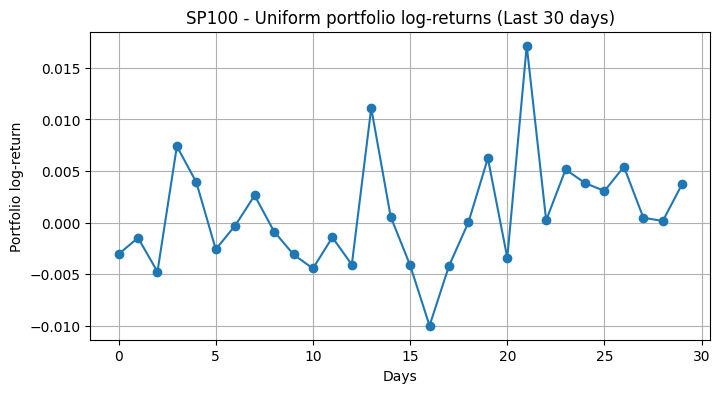

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(portfolio_SP100_last30, marker='o')
plt.title("SP100 - Uniform portfolio log-returns (Last 30 days)")
plt.xlabel("Days")
plt.ylabel("Portfolio log-return")
plt.grid(True)
plt.show()

In [39]:
volatility_SP100_last30_uniform = np.var(portfolio_SP100_last30)

print(f"Volatility of the uniform portfolio over the last 30 days: {volatility_SP100_last30_uniform}")

Volatility of the uniform portfolio over the last 30 days: 2.8136184740527603e-05


**Interpretation**

- The plot of the last 30 days of log-returns of the uniform portfolio shows moderate day-to-day fluctuations, with values oscillating around zero.
- The empirical volatility over the last 30 days is very small ($\texttt{var} = 2.81 \times 10^{-5}$), which corresponds to a daily standard deviation of approximately $\sqrt{\texttt{var}} \approx 0.0053$.
- When weights are spread across nearly 100 assets, individual assets tend to cancel each other out.


# **2.1.2. Unconstrained Optimization**

We assume the stock market returns form a stationary ($n$-variate) time series. Estimate in particular the covariance matrix $C$ by means of the sample covariance matrix of the $n$ stock market (linear) returns $x_1, x_2, \dots \in \mathbb{R}^N$ from 'day1' to '30 days before the end of the recording' (be carefuk to use linear and not log returns).

Using the method of Lagrange multipliers, show that the problem

\begin{equation*}
\arg\min_{w \in \mathbb{R}^n}w^TCw \quad \text{such that} \quad \sum_{i=1}^n w_i = 1
\end{equation*}

has for unique solution

\begin{equation*}
w_{underconstrained} = \frac{C^{-1}\mathbf{1}_n}{\mathbf{1}^T_n C^{-1} \mathbf{1}_n}
\end{equation*}

Implement the formula and compare the values of the returns and the empirical variance now achieved to the uniform case. Comment also on the value of the entries of $w_{underconstrained}$

**Proof**

\begin{equation*}
\arg\min_{w}w^TCw \quad \text{such that} \quad \sum_{i=1}^n w_i = 1 \implies dual gap=0
\end{equation*}

\begin{equation*}
f\left(w\right) = w^TCw
\end{equation*}

\begin{equation*}
L\left(w, \lambda\right) = w^TCw + \lambda \left(\sum_{i=1}^n w_i - 1\right) \quad \text{st} \sum_{i=1}^n w_i = w^T\mathbf{1}_n
\end{equation*}

- We have

\begin{equation*}
\frac{\partial L\left(w, \lambda\right)}{\partial w} = 2Cw + \lambda \mathbf{1}_n = 0 \implies w\left(\lambda\right) = -\frac{w}{2}C^{-1}\mathbf{1}_n
\end{equation*}

- and

\begin{equation*}
g\left(\lambda\right) = \frac{1}{4} \mathbf{1}_n^T C^{-1} \mathbf{1}_n \lambda^2 - \frac{\lambda^2}{2} \mathbf{1}_n^T C^{-1} \mathbf{1}_n - \lambda
\end{equation*}

- So:

\begin{equation*}
\lambda^* = \arg\max_{\lambda}g\left(\lambda\right) \Longleftrightarrow -\frac{1}{2} \lambda^* \mathbf{1}^T_n C^{-1} \mathbf{1}_n -1 = 0 \implies \lambda^* = - \frac{2}{\mathbf{1}^T_nC^{-1}\mathbf{1}_n}
\end{equation*}

- And we have:

\begin{equation*}
w^* = w\left(\lambda^*\right) = \frac{C^{-1}\mathbf{1}_n}{\mathbf{1}^T_n C^{-1} \mathbf{1}_n}
\end{equation*}

- Underconstrained:

\begin{equation*}
w_{underconstrained} = \frac{C^{-1}\mathbf{1}_n}{\mathbf{1}^T_n C^{-1} \mathbf{1}_n}
\end{equation*}

In [9]:
SP100_linear_value = np.exp(SP100_value)

print(f"Size of dataset: {SP100_linear_value.shape}")

SP100_linear_value_train = SP100_linear_value[:, : (n_days - 30)] # for training

print(f"Size of training dataset: {SP100_linear_value_train.shape}")

Size of dataset: (98, 753)
Size of training dataset: (98, 723)


In [10]:
C = np.cov(SP100_linear_value_train)

print(f"Covariance shape: {C.shape}")

Covariance shape: (98, 98)


In [11]:
ones = np.ones(n_assets)

C_inv = np.linalg.inv(C)

numerator = C_inv @ ones

denominator = ones.T @ numerator

w_unconstrained = numerator / denominator

print(f"Sum of weights: {w_unconstrained.sum()}") # must be equal to 1

Sum of weights: 1.0


In [37]:
SP100_linear_value_test = SP100_linear_value[:, -30:] # for testing

portfolio_returns_last30_unconstrained = SP100_linear_value_test.transpose() @ w_unconstrained

volatility_SP100_last30_unconstrained = np.var(portfolio_returns_last30_unconstrained)

print(f"Volatility of the uniform portfolio over the last 30 days (underconstrained): {volatility_SP100_last30_unconstrained}")

Volatility of the uniform portfolio over the last 30 days (underconstrained): 2.6333663040251125e-05


In [38]:
improvement = (volatility_SP100_last30_uniform - volatility_SP100_last30_unconstrained) / volatility_SP100_last30_uniform * 100

print(f"Uniform volatility: {volatility_SP100_last30_uniform}")
print(f"Unconstrained volatility: {volatility_SP100_last30_unconstrained}")

print(f"Risk reduction vs uniform: {improvement:.3f}%")

Uniform volatility: 2.8136184740527603e-05
Unconstrained volatility: 2.6333663040251125e-05
Risk reduction vs uniform: 6.406%


**Interpretation**

- For the SP100 dataset, the unconstrained portfolio achieves a slightly lower variance than the uniform portfolio: relative risk reduction $\approx 6.41%$.
- It shows that taking the covariance structure into account does improve moderate the risk profile of the portfolio.
- Reason:
  - The initial uniform allocation is already highly diversified across 98 assets.
  - The unconstrained optimization tunes the weights by slightly overweighting assets with lower variance and shorting some riskier assets.



# **2.1.3. Constrained Optimization**

The problem of the previous optimization is that it may return negative values for the entries of $w_{underconstrained}$ forcing "short selling". We now assume short selling is impossible (one can only buy and not sell on the market). We thus impose that $[w_i] \geq 0$ for all $i = 1, \dots,n$.

As such, we now consider the constrained optimization problem with positivity constraints on the entries of $w$ that is

\begin{equation*}
\arg\min_{w \in \mathbb{R}^n}w^TCw \quad \text{such that} \quad \sum_{i=1}^n w_i = 1 \quad \text{and} [w]_i \geq 0
\end{equation*}

**Naive approach**

We first propose to solve the problem by means of a single "naive" method consisting in proceeding to a gradient descent method on the unconstrained optimization problem mixed with projections to the constrain set.

Propose and implement such a method (or several approaches) and discuss their associated advantages and limitations.

**For Naive Idea:**
- We ignore the constraint and run gradient descent on $f(w) = w^TCw$.
- After each update, project the point back onto the simplex $\Delta^n$ using the provided algorithm:
  - Gradient on f: $\nabla f(w) = 2Cw$.
  - Update step: $w^{(k+\frac{1}{2})} = w^{(k)} - \alpha \nabla f\left(w^{(k)}\right)$
  - Then project: $w^{(k+1)}=\pi_{\Delta^n}\left(w^\left(k+\frac{1}{2}\right)\right)$

In [14]:
def project_onto_simplex(y):

    y = np.asarray(y, dtype=float)
    n = y.size

    y_sorted = np.sort(y)               # y_(1) <= ... <= y_(n)
    i = n - 1

    while i >= 1:
        t_i = (np.sum(y_sorted[i:]) - 1.0) / (n - i)
        if t_i >= y_sorted[i-1]:
            t_hat = t_i
            break
        i -= 1
    else:
        t_hat = (np.sum(y_sorted) - 1.0) / n

    x = np.maximum(y - t_hat, 0.0)
    return x

In [15]:
def constrained_naive(C, max_iter=2000, eta=0.01, tol=1e-8):

    n = C.shape[0]
    w = np.ones(n) / n
    losses = []

    for k in range(max_iter):
        loss = w @ (C @ w)
        losses.append(loss)

        grad = 2 * (C @ w)
        w_half = w - eta * grad
        w_new = project_onto_simplex(w_half)

        if np.linalg.norm(w_new - w) < tol:
            break

        w = w_new
    return w, losses

In [16]:
w_constrained_naive, losses = constrained_naive(C, max_iter=5000, eta=0.01)

print("Sum w:", w_constrained_naive.sum(),
      "Min w:", w_constrained_naive.min())

Sum w: 1.0 Min w: 0.0


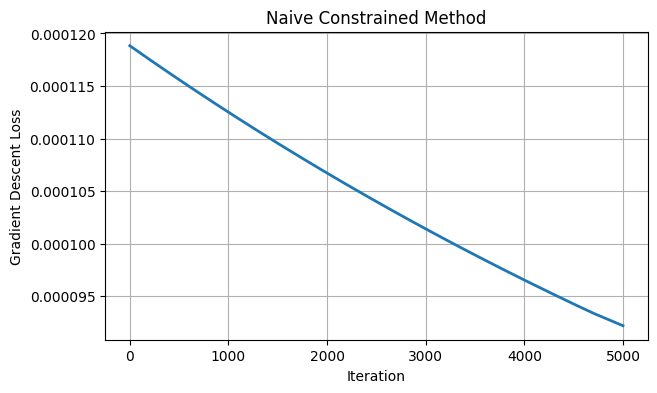

In [17]:
plt.figure(figsize=(7,4))
plt.plot(losses, linewidth=2)
plt.title("Naive Constrained Method")
plt.xlabel("Iteration")
plt.ylabel("Gradient Descent Loss")
plt.grid(True)
plt.show()

In [18]:
returns_constrained_naive = SP100_linear_value[:, -30:].transpose() @ w_constrained_naive
volatility_constrained_naive = np.var(returns_constrained_naive)

print("Naive constrained volatility:", volatility_constrained_naive)

Naive constrained volatility: 2.740328716319331e-05


In [19]:
improvement_unconstrained = (volatility_SP100_last30_uniform - volatility_SP100_last30_unconstrained) / volatility_SP100_last30_uniform * 100
improvement_naive = (volatility_SP100_last30_uniform - volatility_constrained_naive) / volatility_SP100_last30_uniform * 100

print(f"Uniform volatility: {volatility_SP100_last30_uniform}")
print(f"Unconstrained volatility: {volatility_SP100_last30_unconstrained}")
print(f"Naive constrained volatility: {volatility_constrained_naive}\n")

print(f"Risk reduction of Unconstrained vs Uniform: {improvement_unconstrained:.3f}%")
print(f"Risk reduction of Naive vs Uniform: {improvement_naive:.3f}%")

Uniform volatility: 2.8136184740527603e-05
Unconstrained volatility: 2.6333663040251125e-05
Naive constrained volatility: 2.740328716319331e-05

Risk reduction of Unconstrained vs Uniform: 6.406%
Risk reduction of Naive vs Uniform: 2.605%


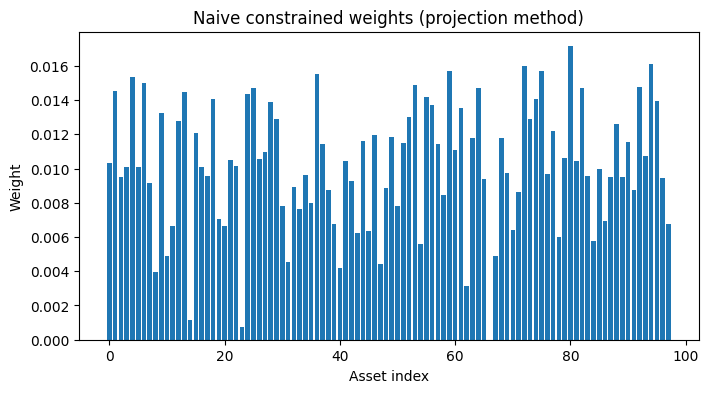

In [29]:
plt.figure(figsize=(8,4))
plt.bar(np.arange(n_assets), w_constrained_naive)
plt.title("Naive constrained weights (projection method)")
plt.xlabel("Asset index")
plt.ylabel("Weight")
plt.show()

**Interpretation**
- Compared to the uniform portfolio, the naive constrained optimizer provides a modest improvement in risk ($\approx 2.6$%) by incorporating the covariance structure of the assets, even though the algorithm is very simple.
- Compared to the unconstrained solution: the naive method necessarily produces a higher volatility because the positivity constraint removes the optimizer's ability to exploit short-selling to offset risk.
- This solution relies on projected gradient descent which:
  - is easy to implement.
  - stays inside the simplex.
  - does not achieve the full efficiency of more advanced methods.

**Advanced optimization**

We now proceed to a careful simplification of the problem by successively (i) *eliminating* the equality constraint (i.e., turning the problem into one with only inequality constraints) and (ii) solving the resulting inequality constrained optimization with a barrier method.

Explain why eliminating the equality constraint is convienient for the proposed barrier optimization approach. Could we have solved the problem differently? (think for instance of dual approaches).

We thus first proceed to the elimination of the equality constraint. To this end, show that we can recast the problem as

\begin{equation*}
\arg\min_{w \in \mathbb{R}^n}w^TCw \quad \text{such that} \quad w = P \bar{w} + \frac{1}{n}\mathbf{1}_n \quad \text{and} \quad [w]_i \geq 0
\end{equation*}

for $P = I_n - \frac{1}{n}\mathbf{1}_n\mathbf{1}_n^T$ the projector operator on the orthogonal complement of span ($1_n$).

Show however that the resulting cost function has a vanishing gradient for all vectors $\bar{w}$ on a non-trivial subspace. What practical implementation problem can that lead to?

To avoid the problem, we now impose $[\bar{w}]_1 = 1$. Show that the solution to the previous problem is equivalent to that of

\begin{equation*}
\arg\min_{w \in \mathbb{R}^{n-1}}w^TCw \quad \text{such that} \quad w = P \left[\frac{1}{\bar{w}}\right] + \frac{1}{n}\mathbf{1}_n \quad \text{and} \quad [w]_i \geq 0
\end{equation*}

As such, the problem can now be solved by a barrier method by relaxing the constraint $[w]_i \geq 0$ for all $i = 1, \dots,n$, by a log-barrier constant $-\mu \sum_{i=1}^{n} \log([w]_i)$. Start by computing the gradient of the new cost function, that is, the gradient with respect to $\bar{w} \in \mathbb{R}^{n-1}$ of

\begin{equation*}
\left(P\begin{bmatrix} \frac{1}{n} \\ \bar{w} \end{bmatrix} + \frac{1}{n}\mathbf{1}_n \right)^TC\left(P\begin{bmatrix} \frac{1}{n} \\ \bar{w} \end{bmatrix} + \frac{1}{n}\mathbf{1}_n\right) -\mu \sum_{i=1}^{n} \log\left(\left[P\begin{bmatrix} \frac{1}{n} \\ \bar{w} \end{bmatrix} + \frac{1}{n}\mathbf{1}_n\right]_i\right)
\end{equation*}

Implement the barrier method to solve the problem. The solution will be denoted $w_{constrained}$ Be especially careful to ensure that each gradient descent step does not break a barrier constraint (backtracking with decreasing step sizes could be used here). A thin control on the progression of the algorithm is also recommended to avoid early stopping.

Finally evaluate the returns $x_t^Tw_{constrained}$ achieved on the last 30 days, plot $w_{constrained}$ and compute the variance of the returns. Compare to the uniform and constrained solutions.

In [20]:
def barrier_setup(n):
    ones = np.ones((n, 1))
    I = np.eye(n)
    P = I - (1.0 / n) * (ones @ ones.T)    # projector

    E = np.zeros((n, n-1))
    E[1:, :] = np.eye(n-1)

    A = P @ E

    e1_over_n = np.zeros((n, 1))
    e1_over_n[0, 0] = 1.0 / n
    b = P @ e1_over_n + (1.0 / n) * ones

    return P, A, b

P, A, b = barrier_setup(n_assets)

In [21]:
def w_from_barw(barw, A, b):
    barw = np.asarray(barw).reshape(-1, 1)  # (n-1, 1)
    w = A @ barw + b                        # (n, 1)
    return w.ravel()

def F_and_grad(barw, C, mu, A, b):
    """
    F(barw) = w^T C w - mu * sum_i log(w_i)
    nablaF(barw) = 2 A^T C w - mu A^T (1 / w)
    """
    w = w_from_barw(barw, A, b)

    if np.any(w <= 0):
        return np.inf, np.zeros_like(barw)

    val = float(w @ (C @ w) - mu * np.sum(np.log(w)))

    grad1 = 2 * (A.T @ (C @ w).reshape(-1, 1))
    grad2 = - mu * (A.T @ (1.0 / w).reshape(-1, 1))
    grad = (grad1 + grad2).ravel()
    return val, grad

In [22]:
def barrier_optimization(C, mu=1e-2, max_iter=5000, tol=1e-6):
    n = C.shape[0]
    P, A, b = barrier_setup(n)

    barw = np.zeros(n-1)

    val, grad = F_and_grad(barw, C, mu, A, b)
    if not np.isfinite(val):
        raise ValueError("Initial point not in domain (w has non-positive entries).")

    for k in range(max_iter):
        val, grad = F_and_grad(barw, C, mu, A, b)
        if np.linalg.norm(grad) < tol:
            break

        d = -grad
        t = 1.0

        # Backtracking line search:
        while True:
            barw_new = barw + t * d
            w_new = w_from_barw(barw_new, A, b)
            if np.any(w_new <= 0):
                t *= 0.5
                if t < 1e-10:
                    break
                continue

            val_new, _ = F_and_grad(barw_new, C, mu, A, b)
            if val_new < val:
                break
            t *= 0.5
            if t < 1e-10:
                break

        if t < 1e-10:
            break

        barw = barw_new

    w_constrained = w_from_barw(barw, A, b)
    w_constrained = project_onto_simplex(w_constrained)
    return w_constrained


In [25]:
w_constrained_barrier = barrier_optimization(C, mu=1e-2)

print(f"Sum w: {w_constrained_barrier.sum():.3f}, "
      f"Min w: {w_constrained_barrier.min():.3f}")

Sum w: 1.000, Min w: 0.010


In [30]:
returns_constrained_barrier = SP100_linear_value[:, -30:].transpose() @ w_constrained_barrier
volatility_constrained_barrier = np.var(returns_constrained_barrier)

print("Barrier constrained volatility:", volatility_constrained_barrier)

Barrier constrained volatility: 2.8359159897377667e-05


In [34]:
improvement_unconstrained = (volatility_SP100_last30_uniform - volatility_SP100_last30_unconstrained) / volatility_SP100_last30_uniform * 100
improvement_naive = (volatility_SP100_last30_uniform - volatility_constrained_naive) / volatility_SP100_last30_uniform * 100
improvement_barrier = (-volatility_SP100_last30_uniform + volatility_constrained_barrier) / volatility_SP100_last30_uniform * 100

print(f"Uniform volatility: {volatility_SP100_last30_uniform}")
print(f"Unconstrained volatility: {volatility_SP100_last30_unconstrained}")
print(f"Naive constrained volatility: {volatility_constrained_naive}")
print(f"Barrier constrained volatility: {volatility_constrained_barrier}\n")

print(f"Risk reduction of Unconstrained vs Uniform: {improvement_unconstrained:.3f}%")
print(f"Risk reduction of Naive vs Uniform: {improvement_naive:.3f}%")
print(f"Risk reduction of Barrier vs Uniform: {improvement_barrier:.3f}%")

Uniform volatility: 2.8136184740527603e-05
Unconstrained volatility: 2.6333663040251125e-05
Naive constrained volatility: 2.740328716319331e-05
Barrier constrained volatility: 2.8359159897377667e-05

Risk reduction of Unconstrained vs Uniform: 6.406%
Risk reduction of Naive vs Uniform: 2.605%
Risk reduction of Barrier vs Uniform: 0.792%


**Interpretation**
- With the dataset SP100, unconstrained behaves with best variance as expected.
- Naive constrained improves uniform but not as much as unconstrained - expected because positivity reduces feasible set.
- But we have a **big problem** here:
  - Barrier returning a higher variance than uniform.
  - It means algorithm either failed to find a good feasible minimum or the barrier parameters pushed the solution to a suboptimal interior point.
  - I think the reasons for this case are:
    - The log-barrier penalizes small weights heavily and forces weights away from near-zero. That prevent concentrating weight on the few favourable assets, so the interior solution may be more uniform => higher volatility.
    - I'm not sure if we have to use ddof = 1 when we calculate the volatility.


In [43]:
print("Without ddof when calculating the volatility")
print(f"Uniform volatility: {volatility_SP100_last30_uniform}")
print(f"Barrier constrained volatility: {volatility_constrained_barrier}\n")

print("With ddof = 1")
print("Uniform volatility (ddof=1):", np.var(portfolio_SP100_last30, ddof=1))
print("Barrier volatility (ddof=1):", np.var(returns_constrained_barrier, ddof=1))

Without ddof when calculating the volatility
Uniform volatility: 2.8136184740527603e-05
Barrier constrained volatility: 2.8359159897377667e-05

With ddof = 1
Uniform volatility (ddof=1): 2.9106398007442347e-05
Barrier volatility (ddof=1): 2.9337061962804483e-05


**As I expected, the result in 2 cases is different.**

In [44]:
print("w_barrier: min, mean, max, n_nonzero:",
      w_constrained_barrier.min(),
      w_constrained_barrier.mean(),
      w_constrained_barrier.max(),
      np.sum(w_constrained_barrier > 1e-6))

# Try smaller mu and rerun
for mu_try in [1e-2, 5e-3, 1e-3, 1e-4]:
    w_try = barrier_optimization(C, mu=mu_try)
    var_try = np.var((SP100_linear_value[:, -30:].T @ w_try), ddof=1)
    print("mu", mu_try, "-> var", var_try)

w_barrier: min, mean, max, n_nonzero: 0.01020154932927182 0.010204081632653064 0.010205661128691305 98
mu 0.01 -> var 2.9337061962804483e-05
mu 0.005 -> var 2.9336749050197494e-05
mu 0.001 -> var 2.9334259952329777e-05
mu 0.0001 -> var 2.9306613876793623e-05


# **Annexe**

The clever trick is to sort the vector (coordinates of the point) $\underline{x}$ to project from smallest to biggest, i.e., $\left(x_1, x_2,\dots,x_n\right) \xrightarrow{} \left(x_{(1)}, x_{(2)},\dots,x_{(n)}\right)$ such that $i<j \Rightarrow x_{(i)} \leq x_{(j)}$. The algorithm can be found as following:


**Algorithm: Projection of $y \in \mathbb{R}^n$ onto the simplex $\Delta ^ n$**

1. Input $y = \left(y_1, \dots, y_n\right)^T \in \mathbb{R}^n$;
2. Sort y in the ascending order as $y_{(1)} \leq \dots \leq y_{(n)}$, and set $i = n - 1$;
3. Compute $t_i = \frac{\sum_{j=i+1}^n y_{(j)} - 1}{n-i}$. If $t_i \geq y_{(i)}$ then set $\hat{t} = t_i$ and go to Step 5, otherwise set $i \xleftarrow{} i-1$ and redo Step 3 if $i \geq 1$ or go to Step 4 if $i=0$;
4. Set $\hat{t} = \frac{\sum_{j=1}^n y_{j} - 1}{n}$;
5. Return $x = \left(y-\hat{t}\right)_+$ as the projection of $y$ on to $\Delta^n$.